Every simulation starts from one thing: numbers that look uniformly random on $(0, 1)$. This page
turns those uniforms into coin tosses, binomials, exponentials, Poissons, betas, normals and
geometrics, then uses them to simulate a single-server queue and compare it with the textbook
formulas, and finishes by estimating areas with random points.

Python and R use different random number generators, so the two versions draw different numbers
even from the same seed. The formulas they are checked against are the same.

To run it yourself: `pip install numpy pandas matplotlib`. Every random number comes from one
generator with a fixed seed, so a top-to-bottom run gives the numbers shown here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

rng = np.random.default_rng(123)

## From uniforms to coin tosses

A toss is heads when $U < p$. With $p = 0.5$, toss a coin 1,000 times and track the running share of
heads. **Predict:** after how many tosses does the share stay within 0.05 of one half?

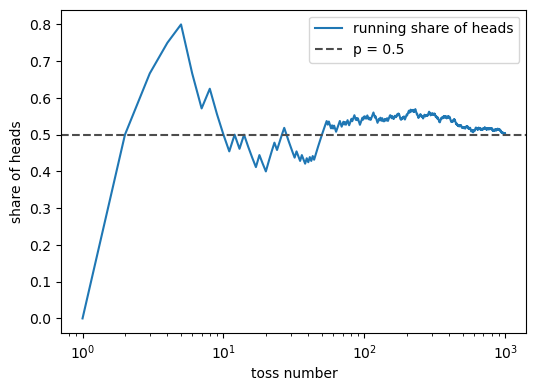

share after 1000 tosses: 0.501 | last toss outside 0.45-0.55: 396


In [2]:
U = rng.random(1000)
heads = (U < 0.5).astype(int)
running = heads.cumsum() / np.arange(1, 1001)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.plot(np.arange(1, 1001), running, label="running share of heads")
ax.axhline(0.5, color="0.3", linestyle="--", label="p = 0.5")
ax.set(xlabel="toss number", ylabel="share of heads", xscale="log")
ax.legend()
plt.show()
outside = np.nonzero(np.abs(running - 0.5) > 0.05)[0]
print("share after 1000 tosses:", running[-1], "| last toss outside 0.45-0.55:", outside[-1] + 1)
# alt: On a log scale of toss number, the running share of heads swings widely over the first few dozen tosses, stays within 0.05 of the dashed line at 0.5 from toss 397 on, and ends at 0.501 after 1,000 tosses.

Each toss is a Bernoulli($p$) variable, and a sum of $n$ of them is Binomial($n$, $p$). With
$n = 1000$ and $p = 0.2$, do this 5,000 times and compare with the built-in binomial generator.
**Predict** the mean and variance.

In [3]:
X_built = (rng.random((5000, 1000)) < 0.2).sum(axis=1)
X_numpy = rng.binomial(1000, 0.2, size=5000)
print(f"built from uniforms: mean {X_built.mean():.2f}, variance {X_built.var():.1f}")
print(f"numpy's binomial:    mean {X_numpy.mean():.2f}, variance {X_numpy.var():.1f}")
print("formulas: np =", 1000 * 0.2, "| np(1 - p) =", 1000 * 0.2 * 0.8)

built from uniforms: mean 200.29, variance 159.3
numpy's binomial:    mean 200.22, variance 160.9
formulas: np = 200.0 | np(1 - p) = 160.0


Any discrete distribution works the same way. Let $P(X=1) = 0.35$, $P(X=2) = 0.15$, $P(X=3) = 0.4$
and $P(X=4) = 0.1$. Stack the probabilities into the cumulative values 0.35, 0.5, 0.9, 1 and return
the first $x$ whose cumulative value reaches $U$.

In [4]:
values = np.array([1, 2, 3, 4])
F = np.cumsum([0.35, 0.15, 0.40, 0.10])
X = values[np.searchsorted(F, rng.random(10_000))]
print("cumulative:", F)
print(pd.Series(X).value_counts(normalize=True).sort_index().round(3).to_string())

cumulative: [0.35 0.5  0.9  1.  ]
1    0.357
2    0.148
3    0.396
4    0.099


## Inverse transform for continuous variables

The same trick for a continuous variable: solve $F(X) = U$ for $X$. Take the density
$f(x) = 2.5\,x^{1.5}$ on $[0, 1]$. Its CDF is $F(x) = x^{2.5}$, so $X = U^{1/2.5} = U^{0.4}$. The exact
mean is $\int_0^1 x \cdot 2.5\,x^{1.5}\,dx = 2.5/3.5 = 5/7$. **Predict:** is a draw more likely to be
above or below 0.5?

In [5]:
X = rng.random(10_000) ** 0.4
print("mean:", X.mean().round(4), "| 5/7 =", round(5 / 7, 4), "| share above 0.5:", (X > 0.5).mean())

mean: 0.7113 | 5/7 = 0.7143 | share above 0.5: 0.817


The exponential with rate $\lambda$ has $F(x) = 1 - e^{-\lambda x}$, so $X = -\ln(1 - U)/\lambda$.
Since $1 - U$ is also uniform, $X = -\ln(U)/\lambda$ works as well.

In [6]:
lam = 1.0
X = -np.log(rng.random(10_000)) / lam
print(f"built: mean {X.mean():.3f}, sd {X.std():.3f} | numpy: mean {rng.exponential(1 / lam, 10_000).mean():.3f} | formula: 1/lambda = {1 / lam}")

built: mean 0.993, sd 1.000 | numpy: mean 1.009 | formula: 1/lambda = 1.0


## Transformations: sums and counts of exponentials

A sum of $n$ independent Exponential($\lambda$) variables is Gamma($n$, $\lambda$), with mean
$n/\lambda$ and variance $n/\lambda^2$. Here $n = 20$, and each row of the array is one gamma draw.

In [7]:
n = 20
X = (-np.log(rng.random((10_000, n))) / lam).sum(axis=1)
print(f"built gamma: mean {X.mean():.2f}, variance {X.var():.2f} | formula: {n / lam}, {n / lam**2}")

built gamma: mean 20.06, variance 19.85 | formula: 20.0, 20.0


Turn it around: count how many exponential inter-arrival times fit into one unit of time. With
arrival rate $\lambda = 2$, that count is Poisson(2). The loop adds gaps until the clock passes 1.
**Predict** the mean and the variance of the count.

In [8]:
lam = 2.0
counts = []
for rep in range(10_000):
    clock, k = -np.log(rng.random()) / lam, 0
    while clock < 1:
        k += 1
        clock += -np.log(rng.random()) / lam
    counts.append(k)
counts = np.array(counts)
print(f"built Poisson: mean {counts.mean():.3f}, variance {counts.var():.3f} | numpy: mean {rng.poisson(lam, 10_000).mean():.3f}")

built Poisson: mean 1.981, variance 2.001 | numpy: mean 1.987


## Acceptance-rejection

Some CDFs cannot be inverted by hand. Beta(2, 4) has density $f(x) = 20x(1-x)^3$ on $[0, 1]$.
Draw a candidate $U_1$ uniformly, and keep it with probability $f(U_1)/c$, where $c$ is the largest
value of $f$. Calculus puts the peak at $x = 1/4$, so $c = 135/64$. Find it numerically first, from the
function on a fine grid.

In [9]:
grid = np.linspace(0, 1, 10_001)
f_grid = 20 * grid * (1 - grid) ** 3
c = f_grid.max()
print("grid max:", round(c, 5), "at x =", grid[f_grid.argmax()], "| 135/64 =", 135 / 64)

grid max: 2.10938 at x = 0.25 | 135/64 = 2.109375


Draw 20,000 candidate pairs $(U_1, U_2)$ and keep $U_1$ whenever $U_2 \le f(U_1)/c$. **Predict:**
what share of candidates is kept? (The area under $f$ is 1, and the box it sits in has area $c$.)

In [10]:
U1, U2 = rng.random(20_000), rng.random(20_000)
kept = U1[U2 <= 20 * U1 * (1 - U1) ** 3 / c]
print(f"kept {kept.size} of 20000 ({kept.size / 20000:.3f}) | 1/c = {1 / c:.3f}")
print(f"mean of kept: {kept.mean():.4f} | Beta(2,4) mean 2/6 = {2 / 6:.4f} | numpy's beta mean: {rng.beta(2, 4, 20_000).mean():.4f}")

kept 9501 of 20000 (0.475) | 1/c = 0.474
mean of kept: 0.3316 | Beta(2,4) mean 2/6 = 0.3333 | numpy's beta mean: 0.3333


## Normals with the Box-Muller method

Two independent uniforms give two independent standard normals:

$$\begin{aligned}
Z_1 &= \sqrt{-2\ln U_1}\,\cos(2\pi U_2) \\
Z_2 &= \sqrt{-2\ln U_1}\,\sin(2\pi U_2)
\end{aligned}$$

It is exact but slow, because of the square root, logarithm, sine and cosine. Below, $Z_1$ is
drawn against the built-in normal generator and the standard normal density.

Z1: mean -0.022, sd 1.002 | Z2: mean -0.011, sd 1.012 | correlation 0.004


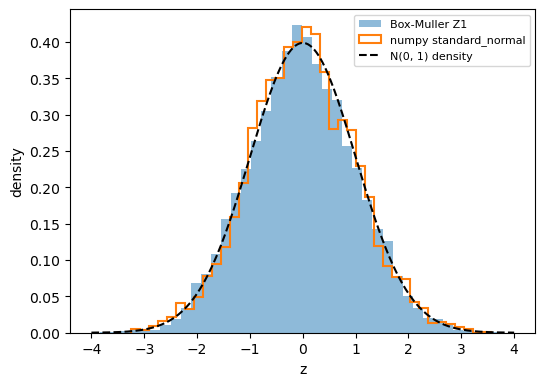

share within 1.96 of 0: 0.949 (Box-Muller), 0.946 (numpy)


In [11]:
U1, U2 = rng.random(5000), rng.random(5000)
Z1 = np.sqrt(-2 * np.log(U1)) * np.cos(2 * np.pi * U2)
Z2 = np.sqrt(-2 * np.log(U1)) * np.sin(2 * np.pi * U2)
print(f"Z1: mean {Z1.mean():.3f}, sd {Z1.std():.3f} | Z2: mean {Z2.mean():.3f}, sd {Z2.std():.3f} | correlation {np.corrcoef(Z1, Z2)[0, 1]:.3f}")
Z3 = rng.standard_normal(5000)
z = np.linspace(-4, 4, 200)
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.hist(Z1, bins=40, density=True, alpha=0.5, label="Box-Muller Z1")
ax.hist(Z3, bins=40, density=True, histtype="step", linewidth=1.5, label="numpy standard_normal")
ax.plot(z, np.exp(-z**2 / 2) / np.sqrt(2 * np.pi), "k--", label="N(0, 1) density")
ax.set(xlabel="z", ylabel="density")
ax.legend(fontsize=8)
plt.show()
print("share within 1.96 of 0:", np.mean(np.abs(Z1) < 1.96).round(3), "(Box-Muller),", np.mean(np.abs(Z3) < 1.96).round(3), "(numpy)")
# alt: The filled Box-Muller histogram and the outlined numpy histogram both follow the dashed bell curve of the standard normal, peaking near 0.4 at z = 0, and about 95% of each sample lies within 1.96 of zero.

## Counting trials: geometric and negative binomial

Repeat Bernoulli($p$) trials until the first success; $K$ is the number of failures plus the one
success. With $p = 0.2$, the mean is $1/p = 5$.

numpy's `geometric` counts trials the same way.

In [12]:
p = 0.2
K = []
for rep in range(10_000):
    k = 1
    while rng.random() > p:
        k += 1
    K.append(k)
print(f"built geometric: mean {np.mean(K):.3f} | numpy: {rng.geometric(p, 10_000).mean():.3f} | 1/p = {1 / p}")

built geometric: mean 4.876 | numpy: 5.017 | 1/p = 5.0


Keep going until $r = 2$ successes and count all the trials: negative binomial, mean $r/p = 10$.

numpy's `negative_binomial` counts only the failures, so add $r$ to compare.

In [13]:
r = 2
trials = []
for rep in range(10_000):
    successes, k = 0, 0
    while successes < r:
        k += 1
        if rng.random() <= p:
            successes += 1
    trials.append(k)
print(f"built: mean {np.mean(trials):.3f} | numpy + r: {(rng.negative_binomial(r, p, 10_000) + r).mean():.3f} | r/p = {r / p}")

built: mean 9.985 | numpy + r: 9.905 | r/p = 10.0


## Queueing metrics

The usual measures of a queue, which carry over to most simulations:

- $L$: average number of jobs in the system; $L_q$: average number waiting in the queue
- $W$: average time a job spends in the system; $W_q$: average time waiting in the queue
- utilisation (share of time the server is busy) and throughput (jobs finished per unit time)
- the distributions of waiting time, system size and queue size, not just their averages

For an M/M/1 queue (exponential arrivals at rate $\lambda$, one exponential server at rate $\mu$,
$\rho = \lambda/\mu < 1$) the averages have formulas. A busy period (from an arrival at an empty
system until it next empties) also has a mean:

$$\begin{aligned}
L &= \frac{\rho}{1 - \rho} \\
W &= \frac{L}{\lambda} = \frac{1}{\mu - \lambda} \\
\text{mean busy period} &= \frac{1}{\mu - \lambda}
\end{aligned}$$

With $\lambda = 0.3$ and $\mu = 1$: $\rho = 0.3$, $L = 0.3/0.7 \approx 0.4286$, and $W$ and the mean
busy period are both $1/0.7 \approx 1.4286$.

## An M/M/1 queue, simulated

Simulate it event by event. With $n$ jobs present, the next event comes after an exponential time at
rate $\lambda + \mu$ (or $\lambda$ if the system is empty), and it is an arrival with probability
$\lambda/(\lambda + \mu)$. Between events, add $n \times$ (time elapsed) to a running area; the area
divided by the clock is the time-average $L$. Run to time 500, ten times.
**Predict:** will all ten estimates of $L$ land within 0.1 of 0.4286?

In [14]:
lam, mu = 0.3, 1.0
rho = lam / mu
horizon, reps = 500, 10
L_sim, busy_share, busy_period = [], [], []
for rep in range(reps):
    clock, n_jobs, area, busy, n_busy_periods = 0.0, 0, 0.0, 0.0, 0
    while clock < horizon:
        rate = lam + mu if n_jobs > 0 else lam
        dt = rng.exponential(1 / rate)
        area += n_jobs * dt
        if n_jobs > 0:
            busy += dt
        clock += dt
        if n_jobs == 0:
            n_jobs, n_busy_periods = 1, n_busy_periods + 1    # an arrival starts a busy period
        elif rng.random() < lam / rate:
            n_jobs += 1                                       # an arrival
        else:
            n_jobs -= 1                                       # a departure
    L_sim.append(area / clock)
    busy_share.append(busy / clock)
    busy_period.append(busy / n_busy_periods)
print("L from each run:", np.round(L_sim, 3))

L from each run: [0.259 0.359 0.383 0.523 0.451 0.46  0.496 0.473 0.455 0.391]


Now the averages over the ten runs beside the formulas. $W$ comes from Little's law, $W = L/\lambda$,
applied to each run.

In [15]:
pd.DataFrame({
    "formula": [rho / (1 - rho), 1 / (mu - lam), rho, 1 / (mu - lam)],
    "simulated (mean of 10)": [np.mean(L_sim), np.mean(L_sim) / lam, np.mean(busy_share), np.mean(busy_period)],
    "sd across runs": [np.std(L_sim, ddof=1), np.std(L_sim, ddof=1) / lam, np.std(busy_share, ddof=1), np.std(busy_period, ddof=1)],
}, index=["L", "W", "utilisation", "mean busy period"]).round(4)

,formula,simulated (mean of 10),sd across runs
L,0.4286,0.4249,0.0778
W,1.4286,1.4164,0.2592
utilisation,0.3000,0.3015,0.0444
mean busy period,1.4286,1.4268,0.1933


## Monte Carlo integration

Estimate $\int_{0.01}^{1} x^{-0.5}\,dx$ (exactly $2(1 - 0.1) = 1.8$) by throwing points into a box and
counting the share that land under the curve. The box spans $x$ from 0.01 to 1 and $y$ from 0 to the
function's largest value on that range, found on a grid as before. **Predict:** with 1,000 points,
how far from 1.8 will the estimate be?

box height 10.00 | hits 195 of 1000 | estimate 1.9305 | exact 1.8


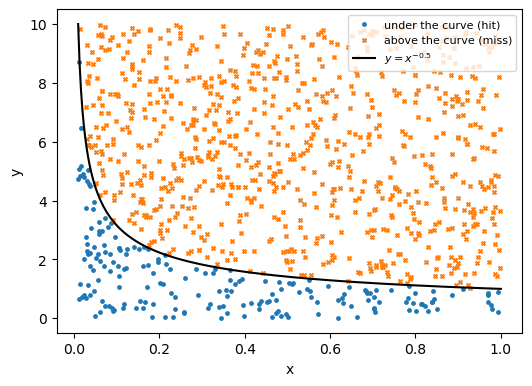

In [16]:
a, b = 0.01, 1.0
height = (np.linspace(a, b, 10_001) ** -0.5).max()
x = rng.uniform(a, b, 1000)
y = rng.uniform(0, height, 1000)
hit = y < x ** -0.5
print(f"box height {height:.2f} | hits {hit.sum()} of 1000 | estimate {(b - a) * height * hit.mean():.4f} | exact 1.8")
fig, ax = plt.subplots(figsize=(6, 4.2))
ax.scatter(x[hit], y[hit], s=6, marker="o", label="under the curve (hit)")
ax.scatter(x[~hit], y[~hit], s=8, marker="x", label="above the curve (miss)")
xs = np.linspace(a, b, 300)
ax.plot(xs, xs ** -0.5, "k-", label=r"$y = x^{-0.5}$")
ax.set(xlabel="x", ylabel="y")
ax.legend(fontsize=8)
plt.show()
# alt: Of 1,000 random points in the box from x = 0.01 to 1 and y = 0 to 10, the 195 dots under the steep curve y = x^-0.5 sit in a thin band along the bottom and a spike at the far left, while the crosses above the curve fill the rest of the box.

The same idea for a semicircle: $\int_{-1}^{1}\sqrt{1 - x^2}\,dx$ is half the area of the unit
circle, $\pi/2$. The box height is the function's largest value on the range, rounded up. Use a
million points this time.

In [17]:
a, b = -1.0, 1.0
height = np.ceil(np.sqrt(1 - np.linspace(a, b, 2001) ** 2).max())
x = rng.uniform(a, b, 1_000_000)
y = rng.uniform(0, height, 1_000_000)
estimate = (b - a) * height * np.mean(y < np.sqrt(1 - x ** 2))
print(f"box height {height:g} | estimate {estimate:.5f} | pi/2 = {np.pi / 2:.5f}")

box height 1 | estimate 1.57148 | pi/2 = 1.57080


## Questions

- The ten simulated values of $L$ are spread out even though the model never changes. Would running
  one simulation to time 5,000 or ten to time 500 give you a better estimate, and why?
- Raise $\lambda$ to 0.9 in the queue and rerun. What happens to $L$ and to the spread across runs?
- Acceptance-rejection threw away about half its candidates. What would happen to that share if $c$
  were set larger than the true maximum, and would the kept values still be Beta(2, 4)?